# Walkthrough: `10_segmentation.py` (Portfolio Split Tests, Interaction Pockets & 5-Year Sufficiency)

### Simple Summary
**This script tests six candidate ways to split the mortgage book (owner-occupied vs. investor, purchase vs. refinance, high LTV, missing FICO/DTI) using Chi-square, Kolmogorov-Smirnov (KS), and KL divergence, discovers high-risk 4-way interaction pockets, and verifies UK PRA Article 180's 5-year minimum history rule per segment.**

> **Safe "Look-But-Don't-Touch" Mode:** This notebook opens the fixed `0.03%` sample (`module2_sample.duckdb`) strictly **read-only in memory** and inspects `chi2_2x2()`, `segmentation_mart`, `interaction_pockets_mart`, and `segment_sufficiency_mart` without touching disk.

---

### Process Flow
<div style="background:#FFFFFF;border:1px solid #CBD5E1;border-radius:8px;padding:14px;max-width:860px;">
<svg viewBox="0 0 820 200" width="100%" xmlns="http://www.w3.org/2000/svg" style="font-family:Segoe UI,Arial,sans-serif;">
  <defs>
    <marker id="arr" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse">
      <path d="M 0 1 L 10 5 L 0 9 z" fill="#64748B"/>
    </marker>
  </defs>
  <rect x="16" y="62" width="175" height="72" rx="6" fill="#051C2C"/>
  <text x="103" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">1. 6 Candidate Splits</text>
  <text x="103" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Chi2, KS &amp; KL divergence</text>
  <line x1="191" y1="98" x2="216" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="220" y="62" width="185" height="72" rx="6" fill="#1E3A8A"/>
  <text x="312" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">2. Risk Pockets</text>
  <text x="312" y="112" text-anchor="middle" fill="#DBEAFE" font-size="10.5">LTV x FICO x Occ x Region</text>
  <line x1="405" y1="98" x2="430" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="434" y="62" width="180" height="72" rx="6" fill="#0E7C7B"/>
  <text x="524" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">3. Art. 180 5y Check</text>
  <text x="524" y="112" text-anchor="middle" fill="#CCFBF1" font-size="10.5">Segment year sufficiency</text>
  <line x1="614" y1="98" x2="639" y2="98" stroke="#64748B" stroke-width="1.8" marker-end="url(#arr)"/>

  <rect x="643" y="62" width="160" height="72" rx="6" fill="#051C2C"/>
  <text x="723" y="92" text-anchor="middle" fill="#FFFFFF" font-size="12.5" font-weight="bold">4. Pockets Visual</text>
  <text x="723" y="112" text-anchor="middle" fill="#CBD5E1" font-size="10.5">Relative risk multipliers</text>
</svg>
</div>

---
### 1. Evaluating Candidate Portfolio Splits (`segmentation_mart`)
Splitting a PD model into separate scorecards only makes sense if two groups differ materially in default rates (Chi-square) *and* risk distributions (KS / KL divergence). Below we attach `module2_sample.duckdb` (`READ_ONLY`), verify `chi2_2x2()` live on the first split, and inspect all six candidate splits.

In [1]:
# Load system, database, dataframe, and plotting libraries
# Import importlib, pathlib, duckdb, pandas, and matplotlib for read-only segmentation inspection
import importlib
import sys
from pathlib import Path
import duckdb
import pandas as pd
import io
import matplotlib.pyplot as plt
from IPython.display import Image, display

# Locate residential_mortgage/ root and register 02_portfolio_analytics/scripts on sys.path
# Walk upward until reaching residential_mortgage/, then insert scripts/ for importing 10_segmentation
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

M2_SCRIPTS = PACKAGE_ROOT / "02_portfolio_analytics/scripts"
if str(M2_SCRIPTS) not in sys.path:
    sys.path.insert(0, str(M2_SCRIPTS))

# Import 10_segmentation and restore Jupyter inline plotting (module2_common sets Agg)
# Switch matplotlib backend back to inline and attach module2_sample.duckdb strictly READ_ONLY
seg_mod = importlib.import_module("10_segmentation")
FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Inspect all 6 candidate splits and re-verify chi2_2x2() live on row 0
# Query m2.segmentation_mart and compare saved chi2_stat against seg_mod.chi2_2x2()
seg_df = con.execute("SELECT * FROM m2.segmentation_mart ORDER BY chi2_stat DESC").fetchdf()
r0 = seg_df.iloc[0]
live_chi2, live_p = seg_mod.chi2_2x2(int(r0["loans_a"]), int(r0["bads_a"]), int(r0["loans_b"]), int(r0["bads_b"]))
print(f"Live chi2_2x2 check on '{r0['candidate_split']}': live={live_chi2:.2f} vs saved={r0['chi2_stat']:.2f}")
seg_df[["candidate_split", "default_rate_a", "default_rate_b", "chi2_stat", "ks_credit_score", "kl_divergence"]].round(4)

Live chi2_2x2 check on 'high_ltv: <=80 vs >80': live=45.11 vs saved=45.11


,candidate_split,default_rate_a,default_rate_b,chi2_stat,ks_credit_score,kl_divergence
0,high_ltv: <=80 vs >80,0.0090,0.0157,45.1087,0.1186,12.4298
1,occupancy: owner-occupied vs investor_second,0.0105,0.0079,4.4227,0.0717,0.3541
2,purpose: purchase vs refinance,0.0094,0.0106,2.2302,0.0402,1.5109
3,missing_dti: present vs missing,0.0101,0.0141,1.5262,0.1750,0.8835
4,missing_credit_score: present vs missing,0.0101,0.0165,0.9757,0.0000,11.4030
5,first_time_buyer: Y vs N,0.0111,0.0100,0.8213,0.0608,1.7257


High LTV (`<=80` vs `>80`), missing DTI/FICO, and loan purpose show highly significant differences in default rates. Next, we inspect the 5-year PRA Article 180 segment sufficiency table and visualize the riskiest multi-factor interaction pockets.

---
### 2. Checking PRA Article 180 5-Year Sufficiency & Visualizing Risk Pockets
Under UK PRA Article 180(1)(h), every rating grade or segment needs at least **5 years** of historical data. Meanwhile, `interaction_pockets_mart` combines `LTV × FICO × Occupancy × Geography` to spot concentrated pockets of risk where single-factor averages hide danger.

,segment_value,years_observed,meets_5y_art180
0,I|R,25,True
1,P|C,25,True
2,P|R,25,True
3,P|P,25,True
4,I|P,25,True
5,S|P,25,True
6,S|R,25,True
7,S|C,24,True
8,I|C,24,True
9,P|U,17,True


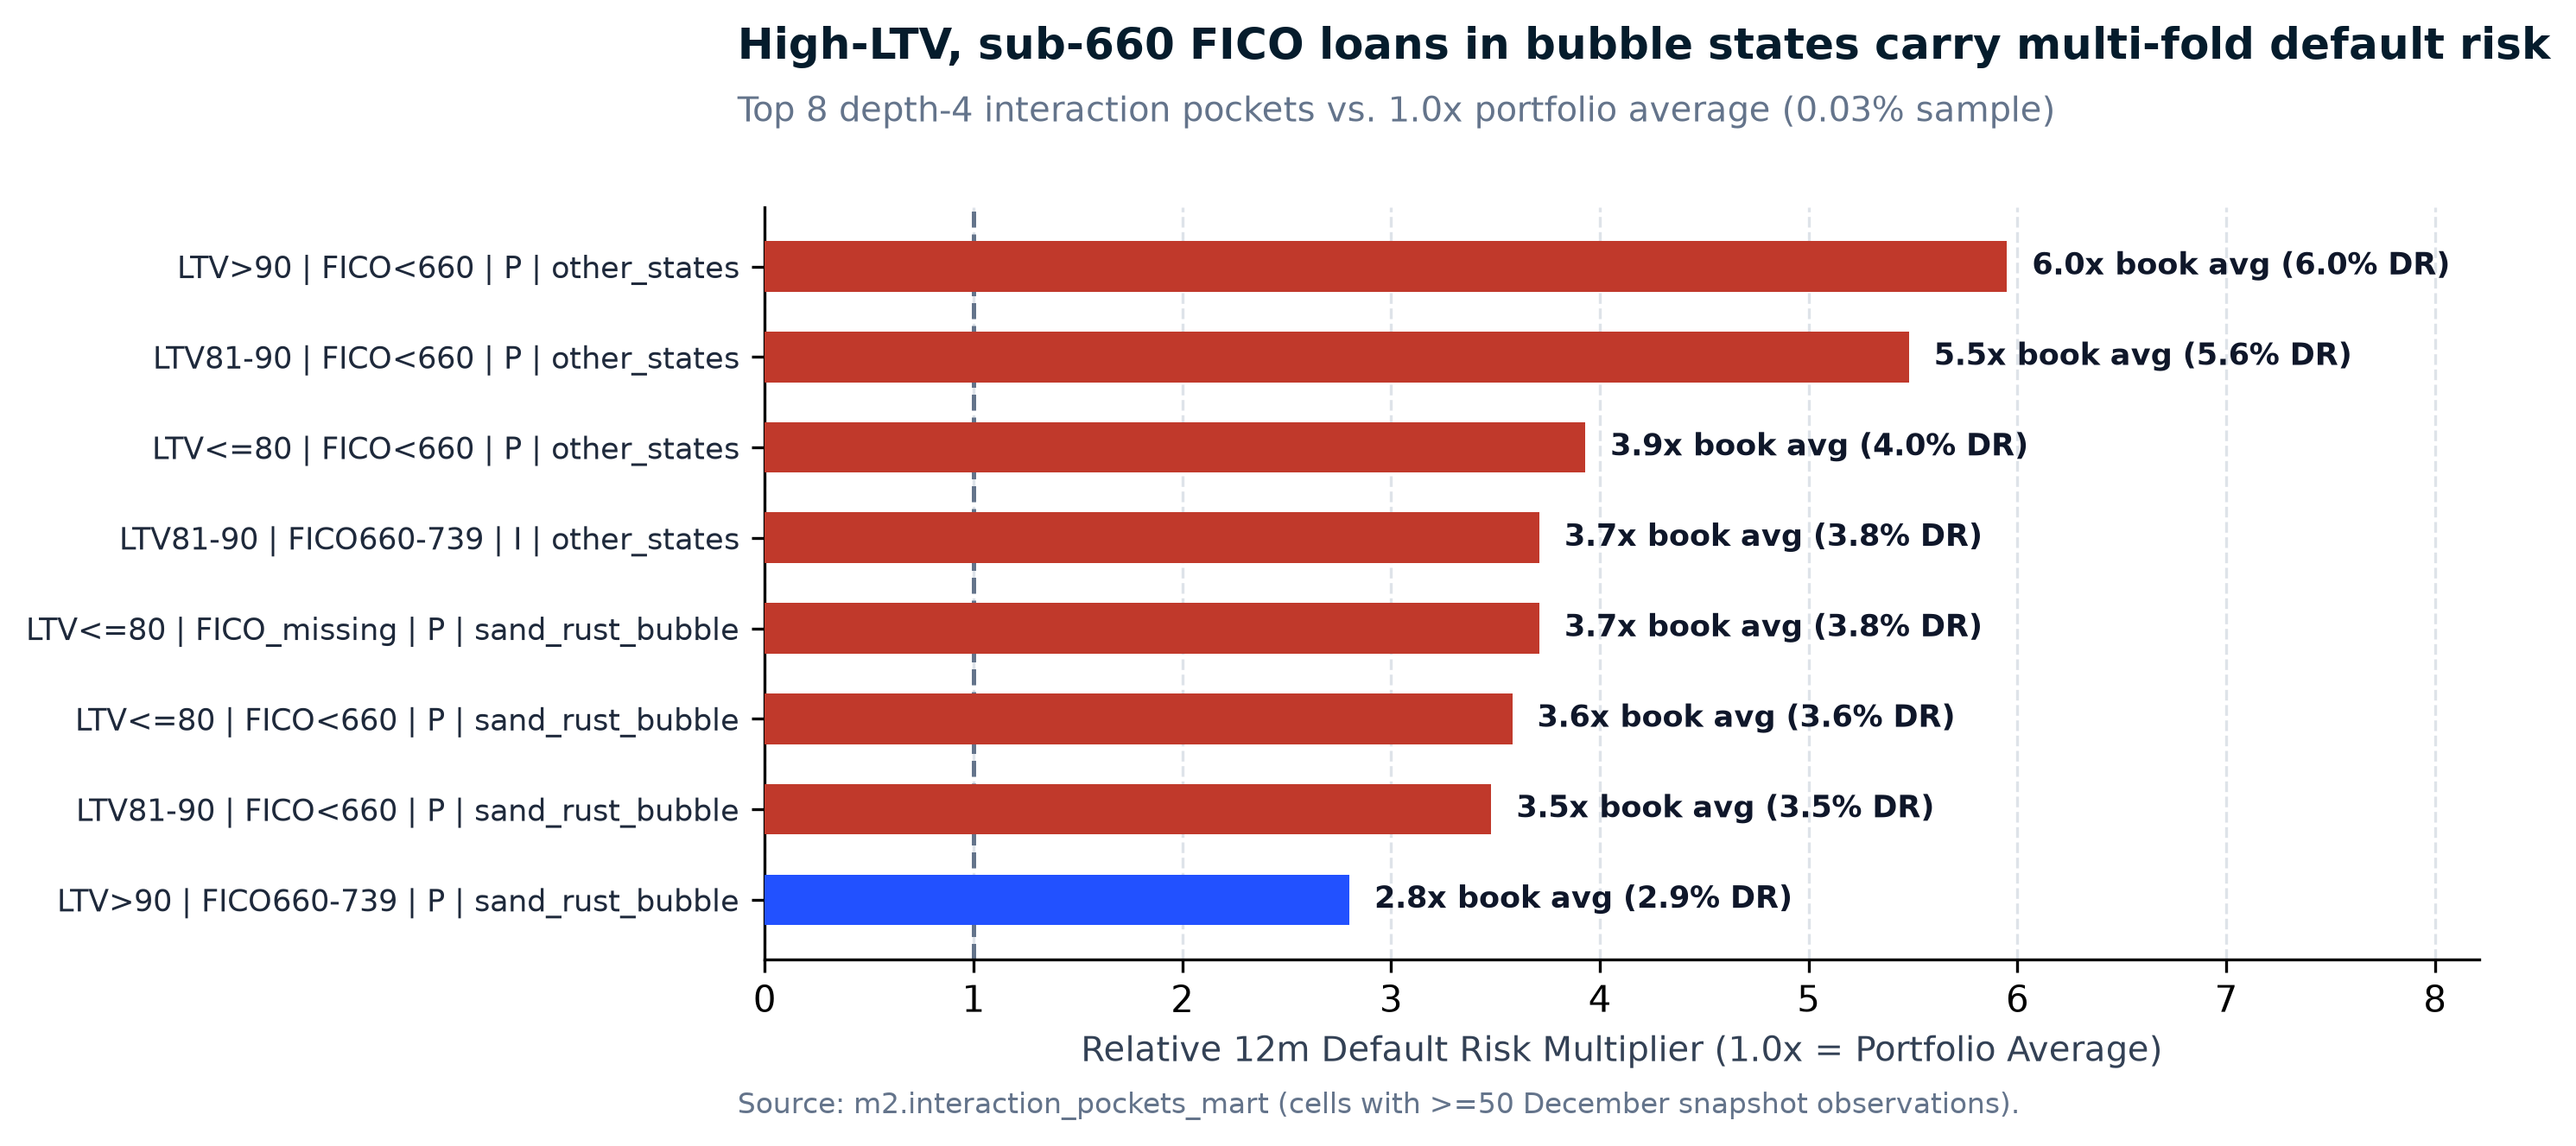

In [2]:
# Check how many segment schemes satisfy Article 180's 5-year minimum history
# Query distinct segments and meets_5y_art180 flags from m2.segment_sufficiency_mart
display(con.execute("""
    SELECT DISTINCT segment_value, years_observed, meets_5y_art180
    FROM m2.segment_sufficiency_mart
    ORDER BY years_observed DESC
""").fetchdf())

# Fetch the top 8 riskiest multi-factor interaction pockets and plot relative risk index at 300 dpi
# Query m2.interaction_pockets_mart ordered by relative_risk_index descending and draw horizontal bars
pock = con.execute("""
    SELECT f1_ltv || ' | ' || f2_fico || ' | ' || f3_occ || ' | ' || f4_region AS pocket_label,
           loans, bads, round(default_rate_12m * 100.0, 2) AS dr_pct, round(relative_risk_index, 2) AS rel_risk
    FROM m2.interaction_pockets_mart
    ORDER BY relative_risk_index DESC
    LIMIT 8
""").fetchdf()

fig, ax = plt.subplots(figsize=(10.5, 4.4), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
bar_colors = ["#C0392B" if v >= 3.0 else "#2251FF" for v in pock["rel_risk"]]
ax.barh(range(len(pock)), pock["rel_risk"], color=bar_colors, height=0.56, zorder=3)
for i, (rr, dr) in enumerate(zip(pock["rel_risk"], pock["dr_pct"])):
    ax.text(rr + 0.12, i, f"{rr:.1f}x book avg ({dr:.1f}% DR)", va="center", fontsize=8.5, fontweight="bold", color="#0F172A")
ax.axvline(1.0, color="#64748B", linestyle="--", linewidth=1.2, zorder=2)
ax.set_yticks(range(len(pock)))
ax.set_yticklabels(pock["pocket_label"], fontsize=8.5, color="#1E293B")
ax.invert_yaxis()
ax.set_xlim(0, pock["rel_risk"].max() * 1.38)
ax.grid(axis="x", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_xlabel("Relative 12m Default Risk Multiplier (1.0x = Portfolio Average)", fontsize=9.5, color="#334155")
fig.text(0.32, 0.94, "High-LTV, sub-660 FICO loans in bubble states carry multi-fold default risk", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.32, 0.885, "Top 8 depth-4 interaction pockets vs. 1.0x portfolio average (0.03% sample)", fontsize=9.5, color="#64748B")
fig.text(0.32, 0.015, "Source: m2.interaction_pockets_mart (cells with >=50 December snapshot observations).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.33, right=0.96, top=0.81, bottom=0.15)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()

Every major `occupancy|purpose` segment meets PRA Article 180's **5-year minimum** (`25 years` observed), and the interaction pockets pinpoint where stacked LTV + FICO + geography risk concentrates. Next, `11_default_outcomes.py` tracks what happens *after* a loan defaults.